# 02 · Modelling results

Training happens in `src/train.py` (run `python -m src.train`). This notebook **reads** what it saved
and examines the results. It does not retrain or re-tune anything.

**Setup recap**
- 80/20 stratified split (seed 42): **519 train** students (80 at risk), **130 test** students (20 at risk).
- Stratified 5-fold CV on the training set for tuning, threshold choice and the "CV" columns.
- **Decision rule:** each model's threshold is the one with the fewest false alarms that still catches **≥ 80%** of at-risk students, chosen on out-of-fold predictions. The test set is scored once at the end.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

from src.data import load_clean
from src.features import VERSION_LABELS
from src.train import CV, get_split, metrics

FIG_DIR = ROOT / "reports" / "figures"
PASS_C, RISK_C = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})

res = pd.read_csv(ROOT / "reports" / "results.csv")
bundles = {v: joblib.load(ROOT / "models" / f"version_{v}.joblib") for v in ["A", "B"]}
df = load_clean("por")
train, test = get_split(df)
for v, b in bundles.items():
    print(f"Version {v}: saved model = {b['model_name']}, threshold = {b['threshold']:.2f}")

Version A: saved model = Random Forest, threshold = 0.34
Version B: saved model = Gradient Boosting, threshold = 0.50


## 1 · Full results table
CV columns are mean ± std across 5 folds. Test columns are one evaluation on the 130 held-out students.

In [2]:
display(Markdown((ROOT / "reports" / "results.md").read_text(encoding="utf-8")))

| Version | Model | CV recall | CV precision | CV ROC-AUC | Test recall | Test precision | Test F1 | Test ROC-AUC |
|---|---|---|---|---|---|---|---|---|
| A: start of year | Dummy (always 'pass') | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.50 ± 0.00 | 0.00 | 0.00 | 0.00 | 0.50 |
| A: start of year | Rule: failures >= 1 | 0.53 ± 0.16 | 0.51 ± 0.15 | 0.71 ± 0.10 | 0.35 | 0.44 | 0.39 | 0.63 |
| A: start of year | Logistic Regression | 0.80 ± 0.11 | 0.32 ± 0.04 | 0.79 ± 0.08 | 0.65 | 0.30 | 0.41 | 0.76 |
| A: start of year | Random Forest | 0.80 ± 0.06 | 0.37 ± 0.04 | 0.84 ± 0.06 | 0.80 | 0.36 | 0.50 | 0.81 |
| A: start of year | Gradient Boosting | 0.80 ± 0.05 | 0.33 ± 0.04 | 0.80 ± 0.05 | 0.75 | 0.28 | 0.41 | 0.78 |
| A + absences (proxy) | Dummy (always 'pass') | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.50 ± 0.00 | 0.00 | 0.00 | 0.00 | 0.50 |
| A + absences (proxy) | Rule: failures >= 1 | 0.53 ± 0.16 | 0.51 ± 0.15 | 0.71 ± 0.10 | 0.35 | 0.44 | 0.39 | 0.63 |
| A + absences (proxy) | Logistic Regression | 0.80 ± 0.11 | 0.33 ± 0.05 | 0.79 ± 0.08 | 0.65 | 0.30 | 0.41 | 0.76 |
| A + absences (proxy) | Random Forest | 0.80 ± 0.07 | 0.36 ± 0.05 | 0.84 ± 0.06 | 0.85 | 0.35 | 0.50 | 0.81 |
| A + absences (proxy) | Gradient Boosting | 0.80 ± 0.05 | 0.34 ± 0.02 | 0.81 ± 0.05 | 0.70 | 0.29 | 0.41 | 0.77 |
| B: after first test | Dummy (always 'pass') | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.50 ± 0.00 | 0.00 | 0.00 | 0.00 | 0.50 |
| B: after first test | Rule: failures >= 1 | 0.53 ± 0.16 | 0.51 ± 0.15 | 0.71 ± 0.10 | 0.35 | 0.44 | 0.39 | 0.63 |
| B: after first test | Rule: G1 < 10 | 0.89 ± 0.11 | 0.61 ± 0.08 | 0.89 ± 0.06 | 0.85 | 0.45 | 0.59 | 0.83 |
| B: after first test | Logistic Regression | 0.81 ± 0.10 | 0.56 ± 0.12 | 0.93 ± 0.03 | 0.85 | 0.52 | 0.64 | 0.90 |
| B: after first test | Random Forest | 0.80 ± 0.11 | 0.65 ± 0.11 | 0.94 ± 0.02 | 0.75 | 0.52 | 0.61 | 0.89 |
| B: after first test | Gradient Boosting | 0.85 ± 0.13 | 0.60 ± 0.09 | 0.94 ± 0.03 | 0.90 | 0.46 | 0.61 | 0.92 |

**How to read the CV recall column:** for the ML models it sits at about **0.80 by design**, because the threshold was chosen to reach 80% recall on these same out-of-fold predictions.
The informative CV columns are **precision** (how many false alarms that recall costs) and **ROC-AUC** (ranking quality, independent of the threshold).
The **test** columns are the honest check.

With only **20 at-risk students in the test set**, one student is worth **5 percentage points** of recall.
Differences smaller than about 10 points between models should not be over-interpreted.

## 2 · Version A: does the start-of-year model beat the simple rule?

In [3]:
a = res[res.version == "A"].set_index("model")
cols = ["cv_recall", "cv_precision", "cv_roc_auc", "test_recall", "test_precision", "test_tp", "test_fp", "test_fn"]
a[cols].round(2)

,cv_recall,cv_precision,cv_roc_auc,test_recall,test_precision,test_tp,test_fp,test_fn
model,,,,,,,,
Dummy (always 'pass'),0.00,0.00,0.50,0.00,0.00,0,0,20
Rule: failures >= 1,0.52,0.51,0.71,0.35,0.44,7,9,13
Logistic Regression,0.80,0.32,0.79,0.65,0.30,13,31,7
Random Forest,0.80,0.37,0.84,0.80,0.36,16,28,4
Gradient Boosting,0.80,0.33,0.80,0.75,0.28,15,38,5


**Observations**
- The rule **"flag if failures ≥ 1"** catches only **35%** of at-risk test students (53% in CV): most struggling students have never failed before.
- The selected **Random Forest catches 80% (16 of 20)** of at-risk test students **on day 1, with no grades**. The cost: about **2 false alarms for every true one** (precision 0.36).
- For a teacher, that's roughly *"a list of 44 students in a cohort of 130, of whom 16 really need help"*. Useful for **cheap, low-stakes** support (a check-in conversation, keeping an eye on them), not for anything punitive.
- All three ML models are close (CV ROC-AUC 0.79–0.84). Model choice matters much less than feature choice here.

## 3 · Does `absences` help the start-of-year model?

In [4]:
cmp = res[res.model.isin(["Logistic Regression", "Random Forest", "Gradient Boosting"]) & res.version.isin(["A", "A_absences"])]
cmp.pivot(index="model", columns="version", values=["cv_roc_auc", "cv_precision", "test_recall"]).round(2)

cv_roc_auc            cv_precision            test_recall  \
version                      A A_absences            A A_absences           A   
model                                                                           
Gradient Boosting         0.80       0.81         0.33       0.34        0.75   
Logistic Regression       0.79       0.79         0.32       0.33        0.65   
Random Forest             0.84       0.84         0.37       0.36        0.80   

                                
version             A_absences  
model                           
Gradient Boosting         0.70  
Logistic Regression       0.65  
Random Forest             0.85

**Observations:** adding `absences` changes CV ROC-AUC by **≤ 0.01** and CV precision by about **0.01** for every model.
It adds almost nothing.

**Decision:** Version A uses **no** `absences`. That costs nothing and removes the time-leakage problem identified in the EDA.

## 4 · Version B: model vs the one-line rule "G1 < 10", compared at the same recall

Comparing the model at 80% recall with the rule at 89% recall is not fair.
Below, the model's threshold is moved (on **out-of-fold** training predictions) to match the rule's recall, then precision is compared.

In [5]:
b = bundles["B"]
X_tr, y_tr = train[b["features"]], train["at_risk"]
oof_b = cross_val_predict(clone(b["pipeline"]), X_tr, y_tr, cv=CV, method="predict_proba")[:, 1]

rule_tr = (train["G1"] < 10).astype(float).to_numpy()
rule_m = metrics(y_tr, rule_tr, 0.5)

prec, rec, thr = precision_recall_curve(y_tr, oof_b)
ok = rec[:-1] >= rule_m["recall"]
i = np.flatnonzero(ok)[np.argmax(prec[:-1][ok])]
model_m = metrics(y_tr, oof_b, thr[i])

pd.DataFrame({
    "Rule: G1 < 10": rule_m,
    f"{b['model_name']} (threshold {thr[i]:.2f})": model_m,
}).loc[["recall", "precision", "f1", "tp", "fp", "fn"]].round(3)

,Rule: G1 < 10,Gradient Boosting (threshold 0.43)
recall,0.888,0.900
precision,0.597,0.558
f1,0.714,0.689
tp,71.000,72.000
fp,48.000,57.000
fn,9.000,8.000


**Observations**
- At the **same recall (~0.89)**, the model is slightly **less** precise than the rule: **0.56 vs 0.60**, i.e. 57 vs 48 false alarms across 519 training students.
  **The model does not beat the one-line rule** at this operating point.
- The model's ROC-AUC is higher (0.94 vs 0.89), but that's partly because the rule only gives yes/no answers.
  The model's real advantage is **ranking**: it can tell a teacher *which* flagged students are most at risk, and *why* (Phase 4).

**Honest conclusion for the README:** once first-period grades exist, **"G1 < 10" is a strong, transparent baseline that the ML model does not beat** on recall and precision.
The value of ML in this project is mainly in **Version A** (before any grades exist), plus risk ranking and explanations in Version B.

## 5 · Precision–recall trade-off on the test set

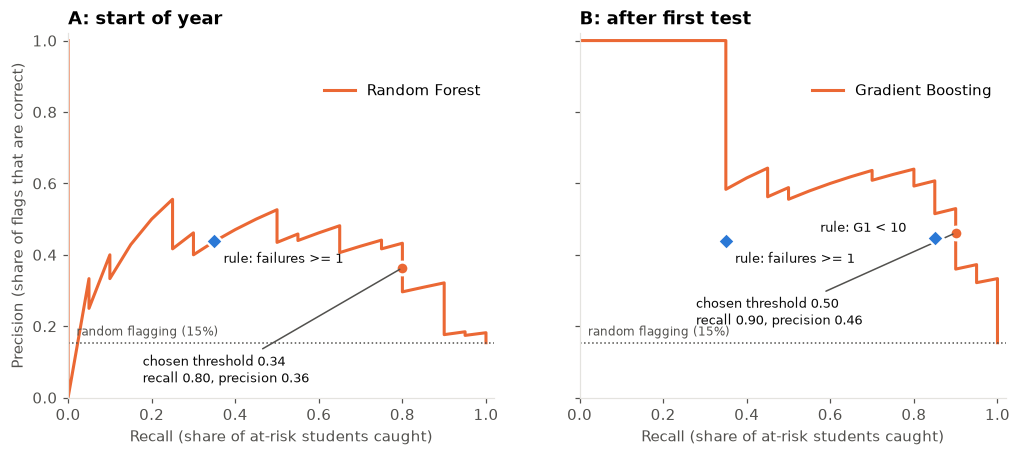

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, v in zip(axes, ["A", "B"]):
    bd = bundles[v]
    p_te = bd["pipeline"].predict_proba(test[bd["features"]])[:, 1]
    prec, rec, _ = precision_recall_curve(test["at_risk"], p_te)
    ax.plot(rec, prec, color=RISK_C, linewidth=2, label=bd["model_name"])
    m = metrics(test["at_risk"], p_te, bd["threshold"])
    ax.scatter([m["recall"]], [m["precision"]], s=70, color=RISK_C, edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"chosen threshold {bd['threshold']:.2f}\nrecall {m['recall']:.2f}, precision {m['precision']:.2f}",
                (m["recall"], m["precision"]), xytext=(-170, -75 if v == "A" else -60), textcoords="offset points",
                fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=INK_2))
    rules = ["Rule: failures >= 1"] + (["Rule: G1 < 10"] if v == "B" else [])
    for r in rules:
        rr = res[(res.version == v) & (res.model == r)].iloc[0]
        ax.scatter([rr.test_recall], [rr.test_precision], s=60, marker="D", color=PASS_C, edgecolor="white", linewidth=1.5, zorder=3)
        ax.annotate(r.replace("Rule: ", "rule: "), (rr.test_recall, rr.test_precision),
                    xytext=(-75, 4) if "G1" in r else (6, -14),
                    textcoords="offset points", fontsize=8.5, color=INK)
    base = test["at_risk"].mean()
    ax.axhline(base, color=INK_2, linestyle=":", linewidth=1)
    ax.text(0.02, base + 0.02, f"random flagging ({base:.0%})", fontsize=8, color=INK_2)
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.grid(axis="both")
    ax.set_xlabel("Recall (share of at-risk students caught)")
    ax.set_title(VERSION_LABELS[v])
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.9))
axes[0].set_ylabel("Precision (share of flags that are correct)")
fig.savefig(FIG_DIR / "07_precision_recall.png", facecolor="white"); plt.show()

**Observations**
- Version B's curve sits well above Version A's: one first-period grade adds a lot of information.
- In Version A, the failures rule (blue diamond) sits **on** the model's curve: at low recall the model is no more precise than the rule.
  The model's advantage is that it can go much further, to 80% recall, where the rule simply runs out of students to flag.
- In Version B, the G1 rule sits right next to the model's chosen point, which confirms section 4.

## 6 · Robustness: results without the 15 probable dropouts (G3 = 0)

In [7]:
pd.read_csv(ROOT / "reports" / "robustness_g3_zero.csv").round(2)

,version,model,recall_all,recall_without_g3_zero,precision_all,precision_without_g3_zero,n_g3_zero_in_test
0,A,Random Forest,0.80,0.81,0.36,0.32,4
1,A_absences,Random Forest,0.85,0.88,0.35,0.31,4
2,B,Gradient Boosting,0.90,0.88,0.46,0.40,4


**Observations:** the test set contains 4 of the G3 = 0 students. Removing them changes recall by ≤ 3 points (less than one student) and lowers precision by 4–6 points, because those 4 were correctly flagged.
Keeping and flagging them (Phase 1 decision) does not distort the conclusions.

## Summary

| | Version A (start of year) | Version B (after first test) |
|---|---|---|
| Selected model | Random Forest | Gradient Boosting |
| Test recall / precision | **0.80 / 0.36** | **0.90 / 0.46** |
| Test ROC-AUC | 0.81 | 0.92 |
| Best simple rule (test recall / precision) | failures ≥ 1: 0.35 / 0.44 | G1 < 10: 0.85 / 0.45 |
| Verdict | ML adds clear value: 2.3× the rule's recall | ML does not beat the G1 rule; value is in ranking + explanations |